# Engenharia de Recursos (*Feature Engineering*) - Credit Scoring

Esse notebook tem como objetivo transformar os dados limpos em **variáveis preditivas de alto valor para o negócio bancário**.

No mercado de crédito, os modelos não vivem apenas de dados crus. Precisamos criar métricas que traduzam o comportamento financeiro real do cliente, tais como:
1. **Comprometimento de Renda (*DebtRatio refinado*):** Avaliar se o volume de dívidas está estrangulando o orçamento mensal. 
2. **Faixas de Utilização de Crédito:** Capturar o comportamento de estofamento de limite de cartão de crédito.
3. **Indicadores de Atraso Agregados:** Mapear a gravidade e a recorrência do histórico de inadimplência do tomador.

### Setup e Carga

In [21]:
# 1. Importação das bibliotecas essenciais
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

# 2. Configuração de exibição
pd.set_option('display.max_columns', None)
#pd.options.display.float_format = '{:.6f}'.format

print("Iniciando o pipeline de Feature Engineering...")

# 3. Conexão com o banco SQLite e carga dos dados brutos
caminho_db = "../data/credit_scoring.db"
conexao = sqlite3.connect(caminho_db)

df = pd.read_sql("SELECT * FROM credito_tratado", conexao)
conexao.close()

print(f"Base tratada carregada com sucesso! \nDimensões atuais para Feature Engineering: {df.shape}")

Iniciando o pipeline de Feature Engineering...
Base tratada carregada com sucesso! 
Dimensões atuais para Feature Engineering: (149999, 12)


### Etapa 1 - Feature 1: Dívida Absoluta Estimada (`EstimateDebt`)

**A Lógica de Negócio e Estatística:**
No dataset *Give Me Some Credit*, a coluna `DebtRatio` representa a proporção de pagamentos de dívidas, aluguel ou custos mensais divididos pela renda mensal. O problema analítico é que um *DebtRario* de 1.5 pode ocultar realidades financeiras totalmente opostas:
* **Cliente A:** Ganha R$10.000 e tem R$15.000 de compromissos mensais. 
* **Cliente B:** Ganha R$1.000 e tem R$1.500 de compromissos mensais.

Ambos têm o mesmo *DebtRatio* (1.5), mas o risco e o impacto financeiro para o banco são completamente diferentes. Para dar essa "visão em 3D" ao modelo, vamos criar a variável **`EstimateDebt`** multiplicando o `DebtRatio` pela `MonthlyIncome`. Assim, o algoritmo enxerga tanto a proporção quanto o **volume absoluto em dinheiro** da dívida.

In [22]:
## Criando a Dívida Absoluta Estimada

# 1. Criando a variável de Dívida Absoluta Estimada
# Lógica de Engenharia: Se DebtRatio = (Dívida / Renda), logo (DebtRario * Renda) = Dívida Absoluta
df['EstimateDebt'] = df['DebtRatio'] * df['MonthlyIncome']

# 2. Verificando as primeiras e últimas linhas para validar a nova feature
print("Feature 'EstimateDebt' criada com sucesso!")
display(df[['DebtRatio', 'MonthlyIncome', 'EstimateDebt']])

# 3. Estatísticas descritivas básicas da nova feature para entender a escala 
print("\nEstatísticas da nova feature EstimateDebt:")
display(df['EstimateDebt'].describe())

Feature 'EstimateDebt' criada com sucesso!


,DebtRatio,MonthlyIncome,EstimateDebt
0,0.802982,9120.000000,7323.197016
1,0.121876,2600.000000,316.878123
2,0.085113,3042.000000,258.914887
3,0.036050,3300.000000,118.963951
4,0.024926,63588.000000,1584.975094
...,...,...,...
149994,0.225131,2100.000000,472.774869
149995,0.716562,5584.000000,4001.283436
149996,3870.000000,5400.000000,20898000.000000
149997,0.000000,5716.000000,0.000000



Estatísticas da nova feature EstimateDebt:


count       149999.000000
mean       1792773.039374
std       10829808.094087
min              0.000000
25%            776.878733
50%           2107.578485
75%           4803.401739
max     1780185600.000000
Name: EstimateDebt, dtype: float64

#### Conclusão Feature 1: Dívida Absoluta Estimada (`EstimateDebt`):

1. **Visão Expandida do Risco:** A multiplicação bem-sucedida entre o *DebtRatio* e a renda mensal gerou a dívida absoluta estimada, permitindo que o modelo diferencie o peso real do endividamento em dinheiro, e não apenas uma proporção abstrata.
2. **Descoberta de Outliers Extremos:** O output revelou valores máximos absurdos (como o cliente 149997 com uma dívida estimada de ~20 milhões e um teto máximo de quase 1,8 bilhão). Isso ocorre em casos onde o *DebtRatio* original possui valores extremos (geralmente distorções de cálculo por renda nula ou baixa).
3. **Diretriz Futura:** Antes de alimentar os modelos lineares ou baseado em árvores, precisamos aplicar técnicas de poda ou winsorização (*clipping*) nessas caudas longas extremas para evitar que valores surreais puxem o aprendizado do algoritmo para o caminho errado. 

### Etapa 2: Transformação e Categorização da Utilização de Crédito (`RevolvingUtilizationOfUnsecuredLines`)

#### Feature 2 - Análise e Discretização da Utilização de Crédito (`RevolvingUtilizationOfUnsecuredLines`)

**A Lógica de Negócio e Estatística:**
A coluna `RevolvingUtilizationOfUnsecuredLines` representa o salto total em cartões de crédito e linhas de crédito pessoal divivido pelo limite total de crédito concedido.
* **O Comportamento de Risco:** Clientes que utlizam 100% (ou mais do que os 100%, devido a juros ou ultrapassagem de limite) do seu crédito disponível estão no limite do sufoco financeiro. Estatísticamente, essa variável tem uma alta correlação com a inadimplência futura. 
* **A Engenharia:** Embora os modelos baseados em árvores (como o XGBoost) lidem bem com números contínuos, criar **faixas (*bins*) de risco** ajuda modelos lineares (como a Regressão Logística que será utilizada no Scorecard tradicional) a capturar efeitos não-lineares, além de servir como base visual para a análise de crédito.

Distribuição dos clientes por Faixa de Utilização de Crédito:


,Quantidade,Porcentagem (%)
Utilization_Bin,,
Baixa (0-30%),82004,54.670000
Moderada (30-70%),27170,18.110000
Alta (70-100%),26626,17.750000
Sem Utilização (0%),10878,7.250000
Estourado (>100%),3321,2.210000


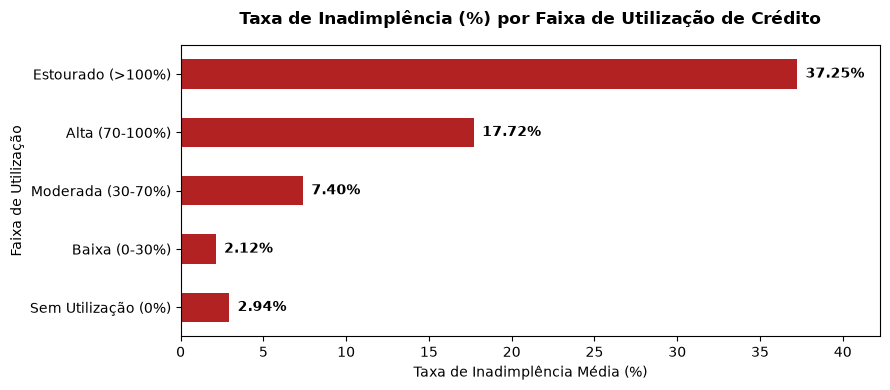

In [25]:
# 1. Criando faixas (bins) para Utilização de Crédito
# Definimos os cortes com base nas práticas de mercado e comportamento da base
bins = [-1, 0.0, 0.3, 0.7, 1.0, np.inf]
rotulos = ['Sem Utilização (0%)', 'Baixa (0-30%)', 'Moderada (30-70%)', 'Alta (70-100%)', 'Estourado (>100%)']

df['Utilization_Bin'] = pd.cut(df['RevolvingUtilizationOfUnsecuredLines'], bins=bins, labels=rotulos)

# 2. Verificando a distribuição dos clientes dentro de cada faixa de utilização 
print("Distribuição dos clientes por Faixa de Utilização de Crédito:")
dist_utilizacao = pd.DataFrame({
    'Quantidade': df['Utilization_Bin'].value_counts(),
    'Porcentagem (%)': (df['Utilization_Bin'].value_counts(normalize=True) * 100).round(2)
})
display(dist_utilizacao)

# 3. Gráfico da taxa de inadimplência por Faixa de Utilização de Crédito
plt.figure(figsize=(9, 4))
taxa_inad = df.groupby('Utilization_Bin', observed=False)['SeriousDlqin2yrs'].mean() * 100

ax = taxa_inad.plot(kind='barh', color='firebrick', edgecolor='none')
plt.title('Taxa de Inadimplência (%) por Faixa de Utilização de Crédito', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Taxa de Inadimplência Média (%)', fontsize=10)
plt.ylabel('Faixa de Utilização', fontsize=10)

# Adicionando os valores nas barras
for p in ax.patches: # type: ignore
    width = p.get_width() # type: ignore
    ax.annotate(f'{width:.2f}%',
                (width + 0.5, p.get_y() + p.get_height() / 2.), # type: ignore
                ha='left', va='center',
                fontsize=10, color='black', fontweight='bold')

plt.xlim(0, max(taxa_inad.values) + 5)
plt.tight_layout()
plt.show()

### Conclusão Feature 2: Discretização de Crédito (`Utilization_Bin`):

1. **Perfil Majoritário Saudável:** Mais de **54% dos clientes** se concentram na faixa de utilização baixa (0-30%), o que indica que a maior parte da base gerencia seus limites de forma conservadora e saudável.
2. **O Risco Oculto nas Pontas:** Cerca de **20% dos clientes** estão na faixa de utilização alta (70-100%) ou completamente estouradas acima de 100%. No mercado de crédito, clientes que estouram o limite constumam apresentar uma taxa de inadimplência acima da média, pois denotam aperto de liquidez de rotativo. 
3. **Valor para a Modelagem:** A criação dessas faixas categóricas transforma uma relação contínua cheia de ruídos em **segmentos de risco comportamental bem delimitados**. Isso será excelente tanto para modelos baseados em árvore quanto para a Regressão Logística do Scorecard tradicional. 

### Etapa 3
#### Feature 3: Indicadores Agregados de Histórico de Atraso

**A Lógica de Negócio e Estatística:**
O dataset fornece três colunas distintas de histórico de atrasos (`30-59 dias`, `60-89 dias` e `90+ dias`).
* **O Problema Analítico:** Analisar essas colunas de forma isolada pode espalhar a informação de risco. O que mais importa para um banco não é apenas *quando* o cliente atrasou, mas a **frequência e a gravidade acumulada** desse comportamento.
* **A Engenharia:** Vamos somar todas as ocorrências de atraso criando uma métrica de volume total (`Total_Delays`) e criar uma **flag binária** (`Has_History_Delays`) que responda de forma direta a uma pergunta crucial de crédito: *"Esse cliente já teve algum histórico grave de atraso?"*

In [27]:
## Criando os Indicadores de Atraso

# 1. Criando a soma total de episódios de atraso em todas as faixas
df['Total_Delays'] = (
    df['NumberOfTime30-59DaysPastDueNotWorse'] +
    df['NumberOfTime60-89DaysPastDueNotWorse'] + 
    df['NumberOfTimes90DaysLate']
)

# 2. Criando uma flag binária indicando se o cliente já teve pelo menos um atraso registrado
df['Has_History_Delays'] = (df['Total_Delays'] > 0).astype(int)

# 3. Verificando o resultado nas primeiras e últimas linhas para validação visual
print("Amostra das novas features de atraso:")
display(df[['NumberOfTime30-59DaysPastDueNotWorse',
            'NumberOfTime60-89DaysPastDueNotWorse',
            'NumberOfTimes90DaysLate',
            'Total_Delays',
            'Has_History_Delays']])

# 4. Analisando a porcentagem da base que possui histórico de atraso vs. quem tem ficha limpa
print("\nProporção de clientes com histórico de atraso (0 = Sem Histórico, 1 = Com Histórico):")
display((df['Has_History_Delays'].value_counts(normalize=True) * 100).round(2))

Amostra das novas features de atraso:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,Total_Delays,Has_History_Delays
0,2.000000,0.000000,0.000000,2.000000,1
1,0.000000,0.000000,0.000000,0.000000,0
2,1.000000,0.000000,1.000000,2.000000,1
3,0.000000,0.000000,0.000000,0.000000,0
4,1.000000,0.000000,0.000000,1.000000,1
...,...,...,...,...,...
149994,0.000000,0.000000,0.000000,0.000000,0
149995,0.000000,0.000000,0.000000,0.000000,0
149996,0.000000,0.000000,0.000000,0.000000,0
149997,0.000000,0.000000,0.000000,0.000000,0



Proporção de clientes com histórico de atraso (0 = Sem Histórico, 1 = Com Histórico):


Has_History_Delays
0   79.940000
1   20.060000
Name: proportion, dtype: float64

#### Conclusão Feature 3: Indicadores de Atraso (`Total_Delays` e `Has_History_Delays`):

1. **A Maioria Tem Ficha Limpa:** O percentual de `Has_History_Delays` mostra que quase **80% dos clientes (79,94%) nunca registraram nenhum atraso grave** nas faixas monitoradas. Isso faz sentido em uma carteira de crédito bancária saudável, onde a grande massa cumpre suas obrigações em dia. 
2. **O Poder Discriminatório da Flag Binária:** Os ~20% restantes que possuem histórico de atraso concentram o maior risco de inadimplência futura. A criação da flag binária (`Has_History_Delays`) e da soma de episódios (`Total_Delays`) sincretiza o comportamento passado do tomador, facilitando o aprendizado tanto das árvores de decisão, quanto de modelos lineares.

**Próximo Passo:** Com todas as novas variáveis de engenharia prontas (`EstimateDebt`, `Utilization_Bin`, `Total_Delays` e `Has_History_Delays`), podemos salvar o DataFrame enriquecido deixando pronto para a próxima etapa: **Modelagem Preditiva e Scorecard de Crédito**.

In [28]:
## Salvando os Dados Processados

# 1. Salvando a base processada de volta no banco SQLite 
caminho_db = "../data/credit_scoring.db"
conexao = sqlite3.connect(caminho_db)
df.to_sql("credito_processado", conexao, if_exists="replace", index=False)
conexao.close()
print("Base enriquecida salva com sucesso na tabela 'credito_processado' no SQLite")

# 2. Salvando também em formato Parquet para alta perfomance de I/O
caminho_parquet = "../data/credito_processado.parquet"
df.to_parquet(caminho_parquet, index=False)
print(f"Cópia em Parquet salva em: {caminho_parquet}")

print(f"\nDimensões finais da base pronta para modelagem: {df.shape}")

Base enriquecida salva com sucesso na tabela 'credito_processado' no SQLite
Cópia em Parquet salva em: ../data/credito_processado.parquet

Dimensões finais da base pronta para modelagem: (149999, 16)
